# Necessary Imports

In [ ]:
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [ ]:
pd.set_option('display.max_columns', None)

# Import training data

In [ ]:
train_df = pd.read_csv('/content/7. swiggy_train_data_imputed.csv')

X_train = train_df.drop(columns = ['time_taken'])
y_train = train_df['time_taken']

In [ ]:
X_train.head()

,rider_age,rider_ratings,multiple_deliveries,vehicle_type,vehicle_condition,distance_km,order_type,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival,weather,traffic
0,32,4.6,1,Scooter,1,6.210138,Snack,15,13,-0.258819,-0.965926,Afternoon,1,0,26,Saturday,0,1,3,0,0,0,Cloudy,High
1,22,4.8,1,Motor-Cycle,0,4.610365,Buffet,10,21,-0.707107,0.707107,Night,0,1,11,Friday,1,0,3,0,0,0,Cloudy,Jam
2,33,4.7,1,Scooter,1,16.600361,Meal,15,19,-0.965926,0.258819,Evening,0,0,4,Friday,1,0,3,0,0,0,Fog,Jam
3,35,4.6,1,Motor-Cycle,2,20.205253,Meal,5,17,-0.965926,-0.258819,Evening,0,0,14,Monday,0,0,3,0,0,0,Cloudy,Medium
4,22,4.8,1,Motor-Cycle,0,19.975520,Buffet,10,20,-0.866025,0.500000,Evening,0,1,20,Sunday,0,1,3,0,0,0,Stormy,Jam


In [ ]:
y_train.head()

,time_taken
0,30
1,26
2,40
3,32
4,34


# Encoding training data

In [ ]:
with open('/content/preprocessor_tree.pkl', 'rb') as f:

     preprocessor = pickle.load(f)

In [ ]:
preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('One-Hot-Encoding',
                                 OneHotEncoder(dtype=<class 'int'>,
                                               handle_unknown='ignore',
                                               sparse_output=False),
                                 ['vehicle_type', 'order_type',
                                  'order_time_of_day', 'order_day_of_week',
                                  'weather']),
                                ('Ordinal-Encoding',
                                 OrdinalEncoder(categories=[['Low', 'Medium',
                                                             'High', 'Jam']],
                                                dtype=<class 'int'>,
                                                handle_unknown='use_encoded_value',
                                                unknown_value=-9999),
                                 ['traffic'])])

In [ ]:
X_train_trf = preprocessor.transform(X_train)

X_train_trf.head()

,One-Hot-Encoding__vehicle_type_Bicycle,One-Hot-Encoding__vehicle_type_Electric-Scooter,One-Hot-Encoding__vehicle_type_Motor-Cycle,One-Hot-Encoding__vehicle_type_Scooter,One-Hot-Encoding__order_type_Buffet,One-Hot-Encoding__order_type_Drinks,One-Hot-Encoding__order_type_Meal,One-Hot-Encoding__order_type_Snack,One-Hot-Encoding__order_time_of_day_Afternoon,One-Hot-Encoding__order_time_of_day_Evening,One-Hot-Encoding__order_time_of_day_Late Night,One-Hot-Encoding__order_time_of_day_Morning,One-Hot-Encoding__order_time_of_day_Night,One-Hot-Encoding__order_day_of_week_Friday,One-Hot-Encoding__order_day_of_week_Monday,One-Hot-Encoding__order_day_of_week_Saturday,One-Hot-Encoding__order_day_of_week_Sunday,One-Hot-Encoding__order_day_of_week_Thursday,One-Hot-Encoding__order_day_of_week_Tuesday,One-Hot-Encoding__order_day_of_week_Wednesday,One-Hot-Encoding__weather_Cloudy,One-Hot-Encoding__weather_Fog,One-Hot-Encoding__weather_Sandstorms,One-Hot-Encoding__weather_Stormy,One-Hot-Encoding__weather_Sunny,One-Hot-Encoding__weather_Windy,Ordinal-Encoding__traffic,remainder__rider_age,remainder__rider_ratings,remainder__multiple_deliveries,remainder__vehicle_condition,remainder__distance_km,remainder__order_pickup_time_mins,remainder__order_placed_hr,remainder__sin_hr,remainder__cos_hr,remainder__is_lunch_rush,remainder__is_dinner_rush,remainder__order_day,remainder__is_friday_night,remainder__is_weekend,remainder__order_month,remainder__is_month_start,remainder__is_month_end,remainder__is_festival
0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,2,32,4.6,1,1,6.210138,15,13,-0.258819,-0.965926,1,0,26,0,1,3,0,0,0
1,0,0,1,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,3,22,4.8,1,0,4.610365,10,21,-0.707107,0.707107,0,1,11,1,0,3,0,0,0
2,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,3,33,4.7,1,1,16.600361,15,19,-0.965926,0.258819,0,0,4,1,0,3,0,0,0
3,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,35,4.6,1,2,20.205253,5,17,-0.965926,-0.258819,0,0,14,0,0,3,0,0,0
4,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,3,22,4.8,1,0,19.975520,10,20,-0.866025,0.500000,0,1,20,0,1,3,0,0,0


# Can we improve XG Boost performance ?

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_validate, RepeatedKFold, KFold
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor

In [ ]:
X_train_sub, X_val, y_train_sub, y_val = train_test_split(X_train_trf, y_train, test_size = 0.2, random_state = 42)

print(X_train_sub.isnull().sum().sum())
print(X_val.isnull().sum().sum())
print(y_train_sub.isnull().sum().sum())
print(y_val.isnull().isnull().sum().sum())

0
0
0
0


### 1.learning_rate

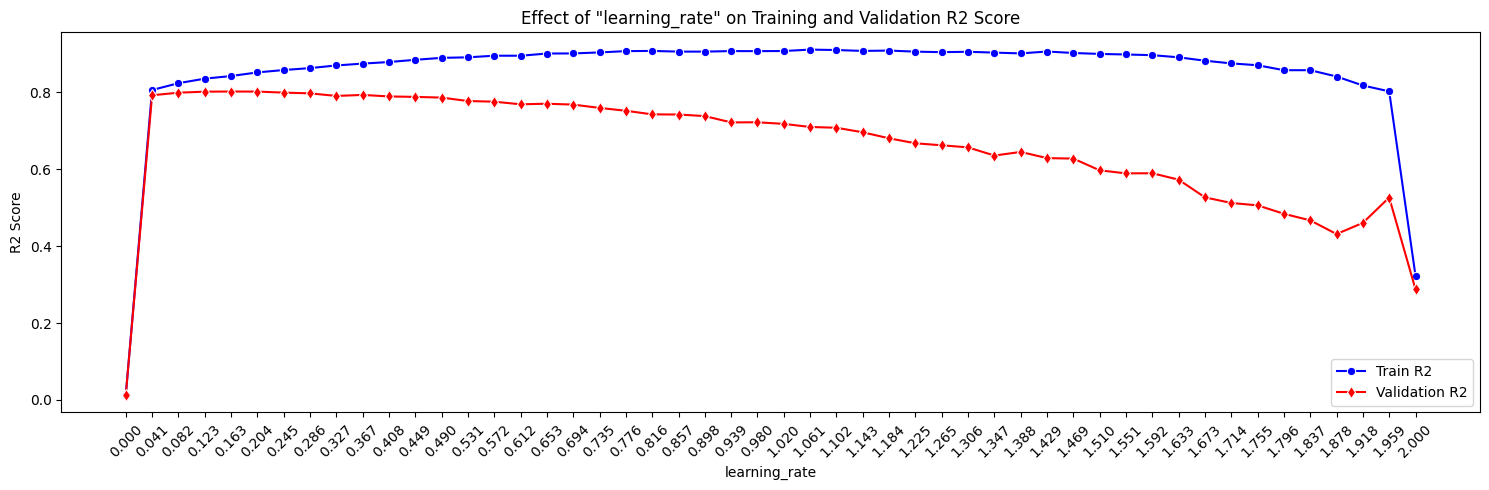

In [ ]:
learning_rate = np.linspace(start = 0.0001, stop = 2)
train_r2_results = []
val_r2_results = []

for i in learning_rate:

    # Training model
    model_reg = XGBRegressor(learning_rate = i, tree_method = 'approx')
    model_reg.fit(X_train_sub, y_train_sub)

    # Prediction on TRAINING Data
    y_train_sub_pred = model_reg.predict(X_train_sub)
    r2_train = r2_score(y_train_sub, y_train_sub_pred)
    train_r2_results.append(r2_train)

    # Prediction on VALIDATION Data
    y_val_pred = model_reg.predict(X_val)
    r2_val = r2_score(y_val, y_val_pred)
    val_r2_results.append(r2_val)

# Plotting Figure
plt.figure(figsize = (15,5))
sns.lineplot(x = learning_rate, y = train_r2_results, marker = 'o', color = 'blue', label = 'Train R2')
sns.lineplot(x = learning_rate, y = val_r2_results,   marker = 'd', color = 'red',  label = 'Validation R2')

# Adding title & Improve Spacing
plt.title('Effect of "learning_rate" on Training and Validation R2 Score')
plt.xticks(learning_rate, rotation = 45)
plt.ylabel('R2 Score')
plt.xlabel('learning_rate')
plt.legend()
plt.tight_layout()
plt.show()

### 2.n_estimators

In [ ]:
print(X_train_sub.isnull().sum().sum())
print(X_val.isnull().sum().sum())
print(y_train_sub.isnull().sum().sum())
print(y_val.isnull().isnull().sum().sum())

0
0
0
0


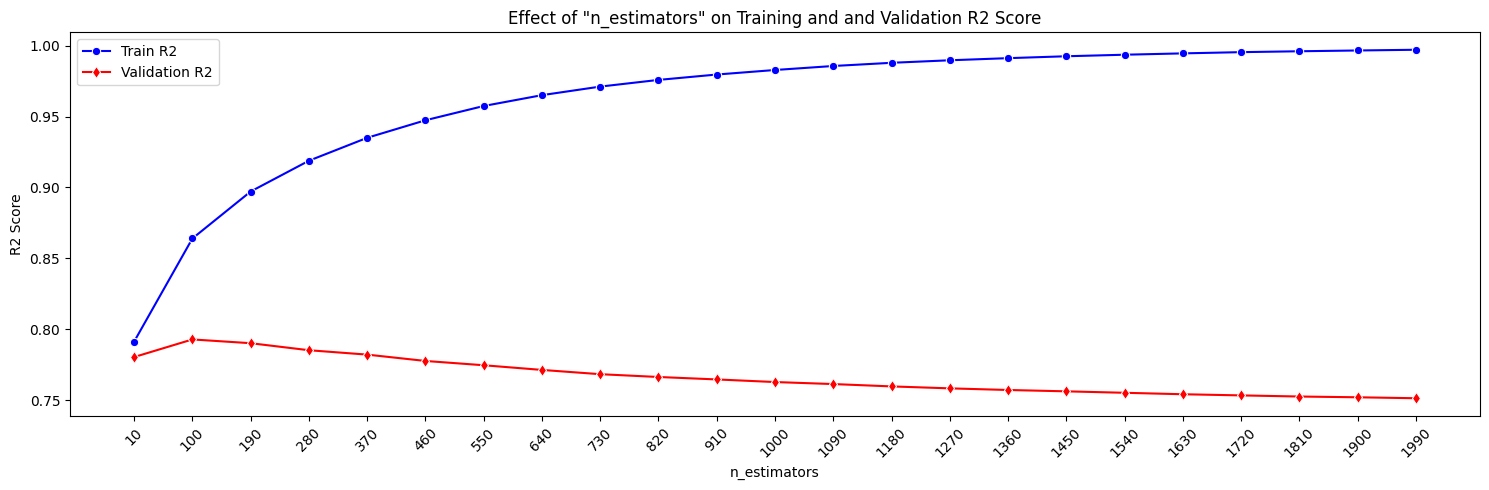

In [ ]:
n_estimators = np.arange(10,2000, step = 90)

train_r2_results = []
val_r2_results = []

for i in n_estimators:

    # Training model
    model_reg = XGBRegressor(n_estimators = i, tree_method = 'hist')
    model_reg.fit(X_train_sub, y_train_sub)

    # Prediction on TRAINING Data
    y_train_sub_pred = model_reg.predict(X_train_sub)
    r2_train = r2_score(y_train_sub, y_train_sub_pred)
    train_r2_results.append(r2_train)

    # Prediction on VALIDATION Data
    y_val_pred = model_reg.predict(X_val)
    r2_val = r2_score(y_val, y_val_pred)
    val_r2_results.append(r2_val)

# Plotting Figure
plt.figure(figsize = (15,5))
sns.lineplot(x = n_estimators, y = train_r2_results, marker = 'o', color = 'blue', label = 'Train R2')
sns.lineplot(x = n_estimators, y = val_r2_results,   marker = 'd', color = 'red',  label = 'Validation R2')

# Adding title & Improve Spacing
plt.title('Effect of "n_estimators" on Training and and Validation R2 Score')
plt.xticks(n_estimators, rotation = 45)
plt.ylabel('R2 Score')
plt.xlabel('n_estimators')
plt.legend()
plt.tight_layout()
plt.show()

### 3.max_depth

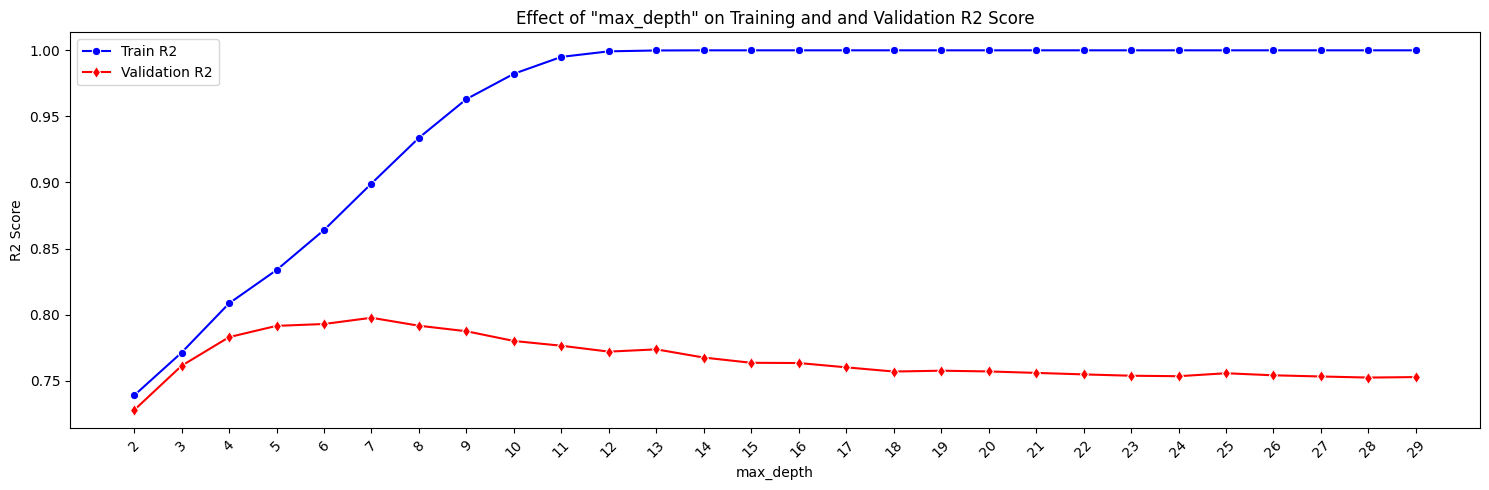

In [ ]:
max_depth = np.arange(2,30, step = 1)

train_r2_results = []
val_r2_results = []

for i in max_depth:

    # Training model
    model_reg = XGBRegressor(max_depth = i, tree_method = 'hist')
    model_reg.fit(X_train_sub, y_train_sub)

    # Prediction on TRAINING Data
    y_train_sub_pred = model_reg.predict(X_train_sub)
    r2_train = r2_score(y_train_sub, y_train_sub_pred)
    train_r2_results.append(r2_train)

    # Prediction on VALIDATION Data
    y_val_pred = model_reg.predict(X_val)
    r2_val = r2_score(y_val, y_val_pred)
    val_r2_results.append(r2_val)

# Plotting Figure
plt.figure(figsize = (15,5))
sns.lineplot(x = max_depth, y = train_r2_results, marker = 'o', color = 'blue', label = 'Train R2')
sns.lineplot(x = max_depth, y = val_r2_results,   marker = 'd', color = 'red',  label = 'Validation R2')

# Adding title & Improve Spacing
plt.title('Effect of "max_depth" on Training and and Validation R2 Score')
plt.xticks(max_depth, rotation = 45)
plt.ylabel('R2 Score')
plt.xlabel('max_depth')
plt.legend()
plt.tight_layout()
plt.show()

### 4.gamma

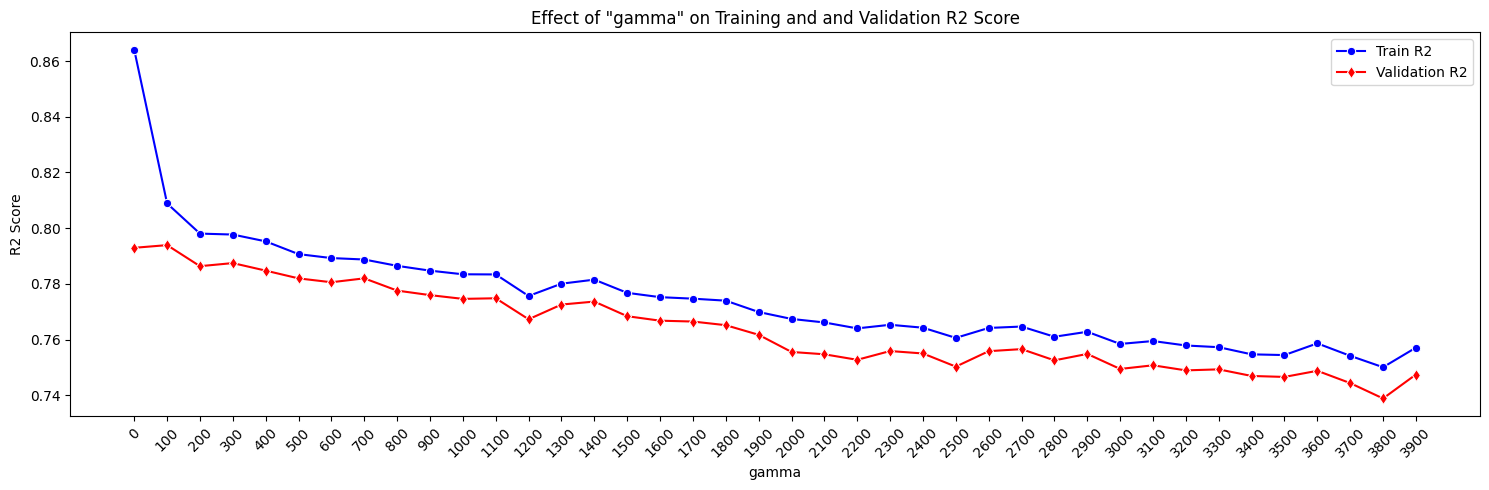

In [ ]:
gammas = np.arange(start = 0, stop = 4000, step = 100)

train_r2_results = []
val_r2_results = []

for i in gammas:

    # Training model
    model_reg = XGBRegressor(min_split_loss = i, tree_method = 'hist')
    model_reg.fit(X_train_sub, y_train_sub)

    # Prediction on TRAINING Data
    y_train_sub_pred = model_reg.predict(X_train_sub)
    r2_train = r2_score(y_train_sub, y_train_sub_pred)
    train_r2_results.append(r2_train)

    # Prediction on VALIDATION Data
    y_val_pred = model_reg.predict(X_val)
    r2_val = r2_score(y_val, y_val_pred)
    val_r2_results.append(r2_val)

# Plotting Figure
plt.figure(figsize = (15,5))
sns.lineplot(x = gammas, y = train_r2_results, marker = 'o', color = 'blue', label = 'Train R2')
sns.lineplot(x = gammas, y = val_r2_results,   marker = 'd', color = 'red',  label = 'Validation R2')

# Adding title & Improve Spacing
plt.title('Effect of "gamma" on Training and and Validation R2 Score')
plt.xticks(gammas, rotation = 45)
plt.ylabel('R2 Score')
plt.xlabel('gamma')
plt.legend()
plt.tight_layout()
plt.show()

### 5.reg_lambda

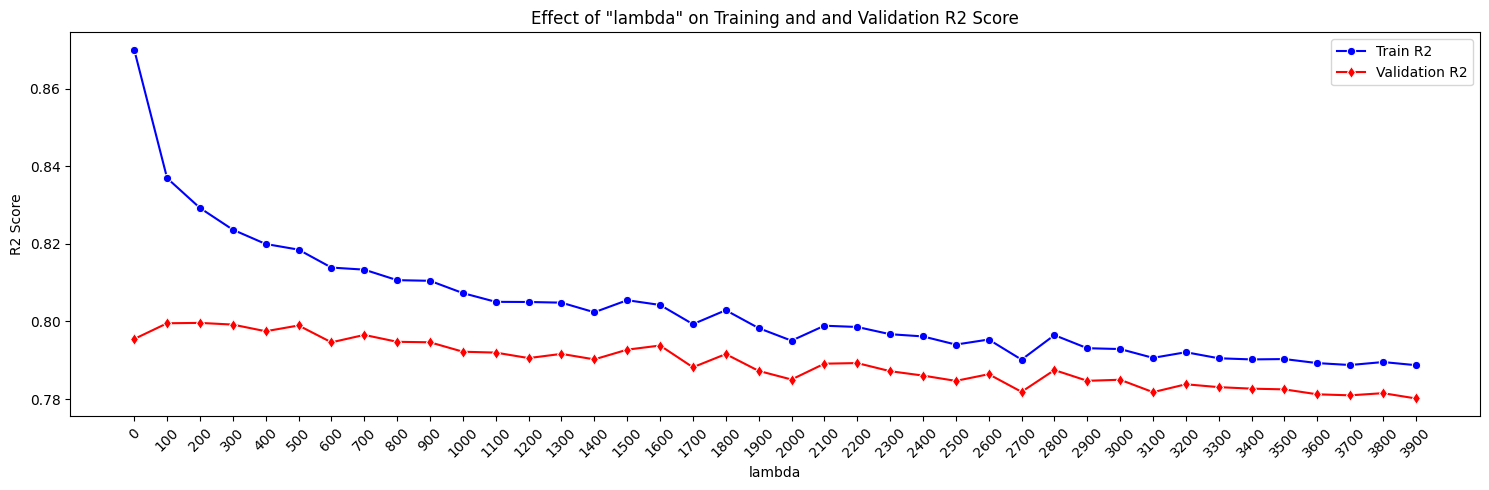

In [ ]:
lambdas = np.arange(start = 0, stop = 4000, step = 100)

train_r2_results = []
val_r2_results = []

for i in lambdas:

    # Training model
    model_reg = XGBRegressor(reg_lambda = i, tree_method = 'hist')
    model_reg.fit(X_train_sub, y_train_sub)

    # Prediction on TRAINING Data
    y_train_sub_pred = model_reg.predict(X_train_sub)
    r2_train = r2_score(y_train_sub, y_train_sub_pred)
    train_r2_results.append(r2_train)

    # Prediction on VALIDATION Data
    y_val_pred = model_reg.predict(X_val)
    r2_val = r2_score(y_val, y_val_pred)
    val_r2_results.append(r2_val)

# Plotting Figure
plt.figure(figsize = (15,5))
sns.lineplot(x = lambdas, y = train_r2_results, marker = 'o', color = 'blue', label = 'Train R2')
sns.lineplot(x = lambdas, y = val_r2_results,   marker = 'd', color = 'red',  label = 'Validation R2')

# Adding title & Improve Spacing
plt.title('Effect of "lambda" on Training and and Validation R2 Score')
plt.xticks(lambdas, rotation = 45)
plt.ylabel('R2 Score')
plt.xlabel('lambda')
plt.legend()
plt.tight_layout()
plt.show()

### 6.Finding XG Boost Optimized Hyper-parameter search region

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 16.1 MB/s eta 0:00:00


In [ ]:
import optuna

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

#### a. Search Space 1

In [ ]:
def objective_xgb_v1(trial):

    learning_rate = trial.suggest_float('xgb_learning_rate', 0.001, 0.5, log = True)
    n_estimators = trial.suggest_int('xgb_n_estimators', 10, 2000)
    max_depth = trial.suggest_int('xgb_max_depth',3, 20)
    gamma = trial.suggest_float('xgb_gamma', 1, 2000)
    reg_lambda = trial.suggest_float('xgb_reg_lambda', 1, 2000)
    min_child_weight = trial.suggest_int('xgb_min_child_weight', 1, 30)
    subsample = trial.suggest_float('xgb_subsample', 0.5, 1.0)
    colsample_bynode = trial.suggest_float('xgb_colsample_bynode', 0.5, 1.0)

    model = XGBRegressor(objective = 'reg:squarederror', tree_method = 'hist', n_estimators = n_estimators, learning_rate = learning_rate, max_depth = max_depth,
                         min_child_weight = min_child_weight, subsample = subsample, colsample_bynode = colsample_bynode, gamma = gamma, reg_lambda = reg_lambda,
                         random_state = 42)

    # K-Fold Cross Validation
    kfold = KFold(n_splits = 5, shuffle = True, random_state = 42)

    # Cross-Validated Scores
    scores = cross_validate(estimator = model, X = X_train_trf, y = y_train, scoring = ['neg_mean_absolute_error', 'r2'], cv = kfold, n_jobs = -1)

    # Cross-Validated Scores
    mean_r2 = scores['test_r2'].mean()
    mean_mae = -scores['test_neg_mean_absolute_error'].mean()

    # Store MAE as additional information for this trial
    trial.set_user_attr('r2', mean_r2)

    # Optimize MAE
    return mean_mae

In [ ]:
name = 'XGBoost_MAE_Round1'

study_xgb_v1 = optuna.create_study(study_name = name, direction ='minimize', sampler = optuna.samplers.TPESampler(seed = 42, n_startup_trials = 30),
                                   pruner = optuna.pruners.MedianPruner() )

study_xgb_v1.optimize(objective_xgb_v1, n_trials = 100, show_progress_bar = True)

  0%|          | 0/100 [00:00<?, ?it/s]

In [ ]:
print('Best MAE:', study_xgb_v1.best_value)
print('Best R2:', study_xgb_v1.best_trial.user_attrs['r2'])

Best MAE: 3.22107515335083
Best R2: 0.8101868391036987


In [ ]:
from optuna.visualization import plot_slice, plot_optimization_history

In [ ]:
plot_optimization_history(study_xgb_v1)

In [ ]:
plot_slice(study_xgb_v1)

#### b. Search Space 2

In [ ]:
def objective_xgb_v2(trial):

    colsample_bynode = trial.suggest_float('xgb_colsample_bynode', 0.8, 1.0, log = True)
    gamma = trial.suggest_float('xgb_gamma', 0.0, 300.0)
    learning_rate = trial.suggest_float('xgb_learning_rate', 0.005, 0.5, log = True)
    max_depth = trial.suggest_int('xgb_max_depth', 7, 30)
    min_child_weight = trial.suggest_int('xgb_min_child_weight', 3, 20)
    n_estimators = trial.suggest_int('xgb_n_estimators', 1500, 3000)
    reg_lambda = trial.suggest_float('xgb_reg_lambda', 0.0, 550.0)
    subsample = trial.suggest_float('xgb_subsample', 0.8, 1.0, log = True)


    model = XGBRegressor(objective = 'reg:squarederror', tree_method = 'hist', n_estimators = n_estimators, learning_rate = learning_rate, max_depth = max_depth,
                         min_child_weight = min_child_weight, subsample = subsample, colsample_bynode = colsample_bynode, gamma = gamma, reg_lambda = reg_lambda,
                         random_state = 42)


    # K-Fold Cross Validation
    kfold = KFold(n_splits = 5, shuffle = True, random_state = 42)

    # Cross-Validated Scores
    scores = cross_validate(estimator = model, X = X_train_trf, y = y_train, scoring = ['neg_mean_absolute_error', 'r2'], cv = kfold, n_jobs = -1)

    # Cross-Validated Scores
    mean_r2 = scores['test_r2'].mean()
    mean_mae = -scores['test_neg_mean_absolute_error'].mean()

    # Store MAE as additional information for this trial
    trial.set_user_attr('r2', mean_r2)

    # Optimize MAE
    return mean_mae

In [ ]:
study_xgb_v2 = optuna.create_study(study_name = 'XGBoost_MAE_Round2', direction ='minimize', sampler = optuna.samplers.TPESampler(seed = 42, n_startup_trials = 15),
                                   pruner = optuna.pruners.MedianPruner())

study_xgb_v2.optimize(objective_xgb_v2, n_trials = 50, show_progress_bar = True)

  0%|          | 0/50 [00:00<?, ?it/s]

In [ ]:
print('Best MAE:', study_xgb_v1.best_value)
print('Best R2:', study_xgb_v1.best_trial.user_attrs['r2'])

Best MAE: 3.22107515335083
Best R2: 0.8101868391036987


In [ ]:
print('Best MAE:', study_xgb_v2.best_value)
print('Best R2:', study_xgb_v2.best_trial.user_attrs['r2'])

Best MAE: 3.208353281021118
Best R2: 0.8115026712417602


In [ ]:
study_xgb_v2.best_params

{'xgb_colsample_bynode': 0.9255624490944472,
 'xgb_gamma': 47.629059763910796,
 'xgb_learning_rate': 0.015061716481473782,
 'xgb_max_depth': 17,
 'xgb_min_child_weight': 7,
 'xgb_n_estimators': 1831,
 'xgb_reg_lambda': 19.073146983390433,
 'xgb_subsample': 0.8741779581645824}

# Can we improve Random-Forest-Regressor performance ?

In [ ]:
def objective_rf(trial):

    n_estimators = trial.suggest_int('rf_n_estimators', 100, 500, step = 100)
    max_depth = trial.suggest_int('rf_max_depth', 5, 30)
    min_samples_split = trial.suggest_int('rf_min_samples_split', 2, 20)
    min_samples_leaf = trial.suggest_int('rf_min_samples_leaf', 1, 10)
    min_impurity_decrease = trial.suggest_float('rf_min_impurity_decrease', 1e-8, 0.01, log = True)
    max_features = trial.suggest_categorical('rf_max_features', ['log2', 'sqrt', 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])

    # Forest Hyperparameters
    bootstrap = trial.suggest_categorical('rf_bootstrap', [True, False])

    if bootstrap:
        max_samples = trial.suggest_float('rf_max_samples', 0.5, 1.0)
    else:
        max_samples = None

    # Model
    regressor_model = RandomForestRegressor(n_estimators = n_estimators, max_depth = max_depth, min_samples_split = min_samples_split,
                                            min_samples_leaf = min_samples_leaf, min_impurity_decrease = min_impurity_decrease, max_features = max_features,
                                            bootstrap = bootstrap, max_samples = max_samples, random_state = 42)


    # K-Fold Cross Validation
    kfold = KFold(n_splits = 5, shuffle = True, random_state = 42)

    # Evaluating Model Performance
    scores = cross_validate(estimator = regressor_model, X = X_train_trf, y = y_train, scoring = ['neg_mean_absolute_error', 'r2'], cv = kfold, n_jobs = -1)

    # Cross-Validated Scores
    mean_r2 = scores['test_r2'].mean()
    mean_mae = -scores['test_neg_mean_absolute_error'].mean()

    trial.set_user_attr('r2', mean_r2)

    return mean_mae

In [ ]:
name_rf = 'Random-Forest Hyperparameter tuning'

study_rf = optuna.create_study(study_name = name_rf, direction = 'minimize', sampler = optuna.samplers.TPESampler(seed = 42, n_startup_trials = 15))

study_rf.optimize(objective_rf, n_trials = 30, show_progress_bar = True)

  0%|          | 0/30 [00:00<?, ?it/s]

In [ ]:
print('Best MAE:', study_rf.best_value)
print('Best R2:',  study_rf.best_trial.user_attrs['r2'])

Best MAE: 3.2181521562286655
Best R2: 0.8098178326039264


In [ ]:
study_rf.best_params

{'rf_n_estimators': 500,
 'rf_max_depth': 18,
 'rf_min_samples_split': 20,
 'rf_min_samples_leaf': 1,
 'rf_min_impurity_decrease': 8.072121880862647e-08,
 'rf_max_features': 0.5,
 'rf_bootstrap': True,
 'rf_max_samples': 0.892197827122572}

# Can we improve Extra-Tree-Regressor Performance ?

In [ ]:
def objective_et(trial):

    n_estimators = trial.suggest_int('et_n_estimators', 100, 500, step = 50)
    max_depth = trial.suggest_int('et_max_depth', 5, 30)
    min_samples_split = trial.suggest_int('et_min_samples_split', 2, 20)
    min_samples_leaf = trial.suggest_int('et_min_samples_leaf', 1, 10)
    min_impurity_decrease = trial.suggest_float('et_min_impurity_decrease', 1e-8, 0.05, log = True)
    max_features = trial.suggest_categorical('et_max_features', ['log2', 'sqrt', 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])

    # Forest Hyperparameters
    bootstrap = trial.suggest_categorical('et_bootstrap', [True, False])

    if bootstrap:
        max_samples = trial.suggest_float('et_max_samples', 0.5, 1.0)
    else:
        max_samples = None

    # Model
    regressor_model = ExtraTreesRegressor(n_estimators = n_estimators, max_depth = max_depth, min_samples_split = min_samples_split, min_samples_leaf = min_samples_leaf,
                                          min_impurity_decrease = min_impurity_decrease, max_features = max_features, bootstrap = bootstrap, max_samples = max_samples,
                                          random_state = 42)

    # K-Fold Cross Validation
    kfold = KFold(n_splits = 5, shuffle = True, random_state = 42)

    # Evaluating Model Performance
    scores = cross_validate(estimator = regressor_model, X = X_train_trf, y = y_train, scoring = ['neg_mean_absolute_error', 'r2'], cv = kfold, n_jobs = -1)

    # Cross-Validated Scores
    mean_r2 = scores['test_r2'].mean()
    mean_mae = -scores['test_neg_mean_absolute_error'].mean()

    trial.set_user_attr('r2', mean_r2)

    return mean_mae

In [ ]:
name_et = 'Extra-Tree Hyperparameter Tuning'

study_et = optuna.create_study(study_name = name_et, direction = 'minimize', sampler = optuna.samplers.TPESampler(seed = 42, n_startup_trials = 15))

study_et.optimize(objective_et, n_trials = 50, show_progress_bar = True)

  0%|          | 0/50 [00:00<?, ?it/s]

In [ ]:
print('Best MAE:', study_et.best_value)
print('Best R2:',  study_et.best_trial.user_attrs['r2'])

Best MAE: 3.2370699544815515
Best R2: 0.807728881782294


In [ ]:
study_et.best_params

{'et_n_estimators': 250,
 'et_max_depth': 15,
 'et_min_samples_split': 18,
 'et_min_samples_leaf': 1,
 'et_min_impurity_decrease': 5.1356168281153344e-08,
 'et_max_features': 1.0,
 'et_bootstrap': False}

# Can we improve Hist-Gradient-Boost-Regressor performance ?

In [ ]:
def objective_hgb(trial):

    learning_rate = trial.suggest_float('hgb_learning_rate', 0.01, 0.3, log=True)
    max_iter = trial.suggest_int('hgb_max_iter', 200, 1200)
    max_depth = trial.suggest_categorical('hgb_max_depth', [None, 2, 3, 4, 5, 6, 7, 8, 9, 10])
    max_leaf_nodes = trial.suggest_int('hgb_max_leaf_nodes', 5, 50)
    min_samples_leaf = trial.suggest_int('hgb_min_samples_leaf', 5, 50)
    l2_regularization = trial.suggest_float('hgb_l2_regularization', 1e-4, 200.0, log = True)
    max_features = trial.suggest_float('hgb_max_features', 0.6, 1.0)

    # Model
    regressor_model = HistGradientBoostingRegressor(loss = 'squared_error', learning_rate = learning_rate, max_iter = max_iter, max_depth = max_depth,
                                                    max_leaf_nodes = max_leaf_nodes, min_samples_leaf = min_samples_leaf, l2_regularization = l2_regularization,
                                                    max_features = max_features, early_stopping = True, validation_fraction = 0.1, scoring = 'loss',
                                                    n_iter_no_change = 20, random_state = 42)

    # K-Fold Cross Validation
    kfold = KFold(n_splits = 5, shuffle = True, random_state = 42)

    # Evaluating Model Performance
    scores = cross_validate(estimator = regressor_model, X = X_train_trf, y = y_train, scoring = ['neg_mean_absolute_error', 'r2'], cv = kfold)

    # Cross-Validated Scores
    mean_r2 = scores['test_r2'].mean()
    mean_mae = -scores['test_neg_mean_absolute_error'].mean()

    trial.set_user_attr('r2', mean_r2)

    return mean_mae

In [ ]:
name_hgb = 'Hist-Gradient-Boost Hyperparameter Tuning'

study_hgb = optuna.create_study(study_name = name_hgb, direction = 'minimize', sampler = optuna.samplers.TPESampler(seed = 42, n_startup_trials = 20))

study_hgb.optimize(objective_hgb, n_trials = 100, show_progress_bar = True)

  0%|          | 0/100 [00:00<?, ?it/s]

In [ ]:
print('Best MAE:', study_hgb.best_value)
print('Best R2:',  study_hgb.best_trial.user_attrs['r2'])

Best MAE: 3.236375559996019
Best R2: 0.8087221793089162


In [ ]:
study_hgb.best_params

{'hgb_learning_rate': 0.0136878585759319,
 'hgb_max_iter': 1099,
 'hgb_max_depth': 10,
 'hgb_max_leaf_nodes': 50,
 'hgb_min_samples_leaf': 5,
 'hgb_l2_regularization': 0.0035358209796969337,
 'hgb_max_features': 0.7761550148921363}

# Can we improve Gradient-Boost-Regressor Performance

In [ ]:
def objective_gbr(trial):

    learning_rate = trial.suggest_float('gbr_learning_rate', 0.01, 0.2, log = True)
    n_estimators = trial.suggest_int('gbr_n_estimators', 100, 800, step = 50)
    max_depth = trial.suggest_int('gbr_max_depth', 2, 8)
    min_samples_split = trial.suggest_int('gbr_min_samples_split', 2, 20)
    min_samples_leaf = trial.suggest_int('gbr_min_samples_leaf', 1, 20)
    min_impurity_decrease = trial.suggest_float('gbr_min_impurity_decrease', 1e-8, 0.05, log = True)
    max_features = trial.suggest_categorical('gbr_max_features', ['sqrt', 0.5, 0.7, 0.85, 1.0])
    subsample = trial.suggest_float('gbr_subsample', 0.6, 1.0)
    max_leaf_nodes = trial.suggest_categorical('gbr_max_leaf_nodes', [None, 15, 31, 63])

    # Model
    regressor_model = GradientBoostingRegressor(loss = 'squared_error', learning_rate = learning_rate, n_estimators = n_estimators,
                                                max_depth = max_depth, min_samples_split = min_samples_split,
                                                min_samples_leaf = min_samples_leaf, min_impurity_decrease = min_impurity_decrease,
                                                max_features = max_features, subsample = subsample, max_leaf_nodes = max_leaf_nodes,
                                                random_state = 42)

    # K-Fold Cross Validation
    kfold = KFold(n_splits = 5, shuffle = True, random_state = 42)

    # Evaluating Model Performance
    scores = cross_validate(estimator = regressor_model, X = X_train_trf, y = y_train, scoring = ['neg_mean_absolute_error', 'r2'], cv = kfold)

    # Cross-Validated Scores
    mean_r2 = scores['test_r2'].mean()
    mean_mae = -scores['test_neg_mean_absolute_error'].mean()

    trial.set_user_attr('r2', mean_r2)

    return mean_mae

In [ ]:
name = 'Gradient-Boost Hyperparameter Tuning'

study_gbr = optuna.create_study(study_name = name, direction = 'minimize', sampler = optuna.samplers.TPESampler(seed = 42, n_startup_trials = 15))

study_gbr.optimize(objective_gbr, n_trials = 30, show_progress_bar = True)

  0%|          | 0/30 [00:00<?, ?it/s]

In [ ]:
print('Best MAE:', study_gbr.best_value)
print('Best R2:',  study_gbr.best_trial.user_attrs['r2'])

Best MAE: 3.2146037051961094
Best R2: 0.8112901066642815


In [ ]:
study_gbr.best_params

{'gbr_learning_rate': 0.011171100217988691,
 'gbr_n_estimators': 650,
 'gbr_max_depth': 8,
 'gbr_min_samples_split': 10,
 'gbr_min_samples_leaf': 3,
 'gbr_min_impurity_decrease': 3.0967935175943103e-06,
 'gbr_max_features': 0.5,
 'gbr_subsample': 0.9714774227209391,
 'gbr_max_leaf_nodes': None}

# Results Comparision

In [ ]:
print('Best MAE:', study_xgb_v1.best_value)
print('Best R2:', study_xgb_v1.best_trial.user_attrs['r2'])

Best MAE: 3.22107515335083
Best R2: 0.8101868391036987


In [ ]:
print('Best MAE:', study_xgb_v2.best_value)
print('Best R2:', study_xgb_v2.best_trial.user_attrs['r2'])

Best MAE: 3.208353281021118
Best R2: 0.8115026712417602


In [ ]:
print('Best MAE:', study_rf.best_value)
print('Best R2:',  study_rf.best_trial.user_attrs['r2'])

Best MAE: 3.2181521562286655
Best R2: 0.8098178326039264


In [ ]:
print('Best MAE:', study_et.best_value)
print('Best R2:',  study_et.best_trial.user_attrs['r2'])

Best MAE: 3.2370699544815515
Best R2: 0.807728881782294


In [ ]:
print('Best MAE:', study_hgb.best_value)
print('Best R2:',  study_hgb.best_trial.user_attrs['r2'])

Best MAE: 3.236375559996019
Best R2: 0.8087221793089162


In [ ]:
print('Best MAE:', study_gbr.best_value)
print('Best R2:',  study_gbr.best_trial.user_attrs['r2'])

Best MAE: 3.2146037051961094
Best R2: 0.8112901066642815


# Checking best hyper-parameter tuned model cross-validated performance

In [ ]:
tuned_rf_model = RandomForestRegressor(n_estimators = 500, max_depth = 18, min_samples_split = 20, min_samples_leaf = 1,
                                       min_impurity_decrease = 8.072121880862647e-08, max_features = 0.5, bootstrap = True,
                                       max_samples = 0.892197827122572, random_state = 42, n_jobs = -1)

In [ ]:
tuned_et_model = ExtraTreesRegressor(n_estimators = 250, max_depth = 15, min_samples_split = 18, min_samples_leaf = 1,
                                     min_impurity_decrease = 5.1356162811553344e-08, max_features = 1.0,
                                     bootstrap = False, max_samples = None, random_state = 42, n_jobs = -1)

In [ ]:
tuned_gbr_model = GradientBoostingRegressor(learning_rate = 0.011171100217988691, n_estimators = 650, max_depth = 8,
                                            min_samples_split = 10, min_samples_leaf = 3, min_impurity_decrease = 3.0967935175943103e-06,
                                            max_features = 0.5, subsample = 0.9714774227209391, max_leaf_nodes = None, random_state = 42)

In [ ]:
tuned_hgb_model = HistGradientBoostingRegressor(loss = 'squared_error', learning_rate = 0.0136878585759319, max_iter = 1099,
                                                max_depth = 10, max_leaf_nodes = 50, min_samples_leaf = 5,
                                                l2_regularization = 0.0035358209796969337, max_features = 0.7761550184921363,
                                                early_stopping = True, validation_fraction = 0.1, scoring = 'loss', n_iter_no_change = 20, random_state = 42)

In [ ]:
tuned_xgb_model = XGBRegressor(objective = 'reg:squarederror', tree_method = 'hist', colsample_bynode = 0.9255624490944472,
                               gamma = 47.629059763910796, learning_rate = 0.015061716481473782, max_depth = 17, min_child_weight = 7,
                               n_estimators = 1831, reg_lambda = 19.073146983390433,
                               subsample = 0.8741779581645824, random_state = 42, n_jobs = -1, verbosity = 0)

In [ ]:
from sklearn.pipeline import Pipeline

In [ ]:
def checking_tuned_models_performace(model_dict:dict, X_train:pd.DataFrame, y_train:pd.Series, preprocessor) -> pd.DataFrame:

    results = []

    for i,j in enumerate(model_dict):

        model_name = j
        model_object = model_dict[model_name]

        print(f'Evaluating Performance of: {model_name}')

        model_pipe = Pipeline(steps = [('Preprocessing', preprocessor),
                                       ('Regressor_Model', model_object)
                                      ])

        # Baseline model cross-validated performances
        rkfold = RepeatedKFold(n_splits = 5, n_repeats = 5, random_state = 42)

        # Evaluating Model performance
        scores = cross_validate(estimator = model_pipe, X = X_train, y = y_train, scoring = ['neg_mean_absolute_error', 'r2'],  cv = rkfold, return_train_score = True)

        # Mean training performance across CV folds
        cv_train_r2 =  scores['train_r2'].mean()
        cv_train_mae = -scores['train_neg_mean_absolute_error'].mean()

        # Mean validation performance across CV folds
        cv_val_r2 = scores['test_r2'].mean()
        cv_val_mae = -scores['test_neg_mean_absolute_error'].mean()

        # Paired generalization gaps
        r2_gap = cv_train_r2 - cv_val_r2
        mae_gap = cv_val_mae - cv_train_mae

        # Validation-score variability
        cv_r2_std = round(scores['test_r2'].std(ddof = 1),4)
        cv_mae_std = round((-scores['test_neg_mean_absolute_error']).std(ddof = 1),4)

        # Appending model performance for DataFrame building
        results.append([model_name, cv_train_r2, cv_val_r2, r2_gap, cv_train_mae, cv_val_mae, mae_gap, cv_r2_std, cv_mae_std])

    # Creating DataFrame
    columns_name = ['model_name', 'cv_train(R2)', 'cv_val(R2)', 'r2_gap', 'cv_train(MAE)', 'cv_val(MAE)', 'mae_gap', 'cv_r2_std', 'cv_mae_std']
    tuned_result_df = pd.DataFrame(data = results, columns = columns_name)

    # Sorting logic
    tuned_result_df.sort_values(by = ['cv_val(MAE)', 'cv_val(R2)', 'mae_gap', 'r2_gap'], ascending = [True, False, True, True], inplace = True)
    tuned_result_df.reset_index(drop = True, inplace = True)

    # return DataFrame
    return tuned_result_df.round(4)

In [ ]:
tuned_models_dict = {'Random-Forest-tuned': tuned_rf_model,
                     'Extra-Tree-tuned': tuned_et_model,
                     'Gradient-Boosting-tuned': tuned_gbr_model,
                     'Hist-Gradient-Boosting-tuned': tuned_hgb_model,
                     'XG-Boost-tuned': tuned_xgb_model}

In [ ]:
tuned_result_df = checking_tuned_models_performace(tuned_models_dict, X_train, y_train, preprocessor)

Evaluating Performance of: Random-Forest-tuned
Evaluating Performance of: Extra-Tree-tuned
Evaluating Performance of: Gradient-Boosting-tuned
Evaluating Performance of: Hist-Gradient-Boosting-tuned
Evaluating Performance of: XG-Boost-tuned


In [ ]:
tuned_result_df

,model_name,cv_train(R2),cv_val(R2),r2_gap,cv_train(MAE),cv_val(MAE),mae_gap,cv_r2_std,cv_mae_std
0,XG-Boost-tuned,0.8515,0.8112,0.0403,2.8890,3.2084,0.3194,0.0052,0.0275
1,Gradient-Boosting-tuned,0.8584,0.8112,0.0471,2.7981,3.2146,0.4165,0.0054,0.0298
2,Random-Forest-tuned,0.8766,0.8095,0.0671,2.6007,3.2192,0.6186,0.0054,0.0288
3,Extra-Tree-tuned,0.8779,0.8077,0.0702,2.5847,3.2366,0.6520,0.0052,0.0322
4,Hist-Gradient-Boosting-tuned,0.8316,0.8084,0.0232,3.0631,3.2385,0.1754,0.0053,0.0309


In [ ]:
tuned_result_df.to_csv('4. tuned_models_result.csv', index = False)

# Bias-Variance Trade-off

In [ ]:
!pip install mlxtend

In [ ]:
from mlxtend.evaluate import bias_variance_decomp
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import train_test_split

In [ ]:
tuned_models_dict = {'Random-Forest-tuned': tuned_rf_model,
                     'Extra-Tree-tuned': tuned_et_model,
                     'Gradient-Boosting-tuned': tuned_gbr_model,
                     'Hist-Gradient-Boosting-tuned': tuned_hgb_model,
                     'XG-Boost-tuned': tuned_xgb_model}

In [ ]:
X_train_sub, X_val, y_train_sub, y_val = train_test_split(X_train, y_train, test_size = 0.2, random_state = 42)

feature_names =  X_train.columns.tolist() # Original feature names and order

feature_dtypes = X_train.dtypes.to_dict() # Original data type

feature_dtypes

{'rider_age': dtype('int64'),
 'rider_ratings': dtype('float64'),
 'multiple_deliveries': dtype('int64'),
 'vehicle_type': dtype('O'),
 'vehicle_condition': dtype('int64'),
 'distance_km': dtype('float64'),
 'order_type': dtype('O'),
 'order_pickup_time_mins': dtype('int64'),
 'order_placed_hr': dtype('int64'),
 'sin_hr': dtype('float64'),
 'cos_hr': dtype('float64'),
 'order_time_of_day': dtype('O'),
 'is_lunch_rush': dtype('int64'),
 'is_dinner_rush': dtype('int64'),
 'order_day': dtype('int64'),
 'order_day_of_week': dtype('O'),
 'is_friday_night': dtype('int64'),
 'is_weekend': dtype('int64'),
 'order_month': dtype('int64'),
 'is_month_start': dtype('int64'),
 'is_month_end': dtype('int64'),
 'is_festival': dtype('int64'),
 'weather': dtype('O'),
 'traffic': dtype('O')}

In [ ]:
preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('One-Hot-Encoding',
                                 OneHotEncoder(dtype=<class 'int'>,
                                               handle_unknown='ignore',
                                               sparse_output=False),
                                 ['vehicle_type', 'order_type',
                                  'order_time_of_day', 'order_day_of_week',
                                  'weather']),
                                ('Ordinal-Encoding',
                                 OrdinalEncoder(categories=[['Low', 'Medium',
                                                             'High', 'Jam']],
                                                dtype=<class 'int'>,
                                                handle_unknown='use_encoded_value',
                                                unknown_value=-9999),
                                 ['traffic'])])

In [ ]:
import time

In [ ]:
def convert_to_DataFrame(X):

    return pd.DataFrame(data = X, columns = feature_names).astype(feature_dtypes)

In [ ]:
start = time.time()

results = []

for model_name, model_object in tuned_models_dict.items():

    print('Evaluating:', model_name)

    model_pipeline = Pipeline(steps = [('Function-Tranformer', FunctionTransformer(convert_to_DataFrame)),
                                       ('preprocessing', preprocessor),
                                       ('model', model_object)
                                      ])

    average_expected_loss, avg_bias, avg_var = bias_variance_decomp(model_pipeline, X_train_sub.to_numpy(), y_train_sub.to_numpy(),
                                                                    X_val.to_numpy(), y_val.to_numpy(), loss = 'mse', num_rounds = 50, random_seed = 42)


    results.append([model_name, average_expected_loss, avg_bias, avg_var])

end = time.time()

Evaluating: Random-Forest-tuned
Evaluating: Extra-Tree-tuned
Evaluating: Gradient-Boosting-tuned
Evaluating: Hist-Gradient-Boosting-tuned
Evaluating: XG-Boost-tuned


In [ ]:
print(f'Time taken: {round((end - start)/3600,2)} hr')

Time taken: 2.12 hr


In [ ]:
tuned_bias_var_decomp_df = pd.DataFrame(data = results, columns = ['model_name', 'average_expected_loss', 'avg_bias', 'avg_var'])

In [ ]:
tuned_bias_var_decomp_df

,model_name,average_expected_loss,avg_bias,avg_var
0,Random-Forest-tuned,17.684278,17.148854,0.535424
1,Extra-Tree-tuned,17.906514,17.328761,0.577754
2,Gradient-Boosting-tuned,17.336952,16.962159,0.374793
3,Hist-Gradient-Boosting-tuned,17.538632,17.076733,0.461898
4,XG-Boost-tuned,17.678731,17.114130,0.564602


In [134]:
# Exporting them

tuned_bias_var_decomp_df.to_csv('5. tuned_bias_var_decomp.csv', index = False)

# Deciding final model

In [156]:
# baseline results
baseline_results = pd.read_csv('/content/1. baseline_models_result.csv')
baseline_bias_var_results = pd.read_csv('/content/2. baseline_bias_var_decomp.csv')

# tuned results
tuned_results = pd.read_csv('/content/4. tuned_models_result.csv')
tuned_bias_var_results = pd.read_csv('/content/5. tuned_bias_var_decomp.csv')

In [212]:
temp1 = baseline_results.merge(baseline_bias_var_results, on = 'model_name', how = 'inner')

temp2 = tuned_results.merge(tuned_bias_var_results, on = 'model_name', how = 'inner')

all_models_result = pd.concat([temp1, temp2], axis = 0).reset_index(drop = True)

all_models_result.sort_values(by = ['cv_val(MAE)', 'cv_val(R2)', 'mae_gap', 'r2_gap', 'cv_train(MAE)'], ascending = [True, False, True, True, True], inplace = True)

all_models_result.reset_index(drop = True, inplace = True)

In [213]:
all_models_result.head()

,model_name,cv_train(R2),cv_val(R2),r2_gap,cv_train(MAE),cv_val(MAE),mae_gap,cv_r2_std,cv_mae_std,average_expected_loss,avg_bias,avg_var
0,XG-Boost-tuned,0.8515,0.8112,0.0403,2.8890,3.2084,0.3194,0.0052,0.0275,17.678731,17.114130,0.564602
1,Gradient-Boosting-tuned,0.8584,0.8112,0.0471,2.7981,3.2146,0.4165,0.0054,0.0298,17.336952,16.962159,0.374793
2,Random-Forest-tuned,0.8766,0.8095,0.0671,2.6007,3.2192,0.6186,0.0054,0.0288,17.684278,17.148854,0.535424
3,Extra-Tree-tuned,0.8779,0.8077,0.0702,2.5847,3.2366,0.6520,0.0052,0.0322,17.906514,17.328761,0.577754
4,Hist-Gradient-Boosting-tuned,0.8316,0.8084,0.0232,3.0631,3.2385,0.1754,0.0053,0.0309,17.538632,17.076733,0.461898
5,Hist-Gradient-Boosting-baseline,0.8192,0.8026,0.0166,3.1552,3.2811,0.1259,0.0054,0.0307,18.126368,17.698708,0.427660
6,Random-Forest-baseline,0.9718,0.7983,0.1735,1.2186,3.2927,2.0741,0.0057,0.0286,19.046354,17.561632,1.484723
7,XG-Boost-baseline,0.8666,0.7996,0.0670,2.7202,3.3190,0.5988,0.0057,0.0304,18.949870,17.225467,1.724404
8,Extra-Tree-baseline,1.0000,0.7936,0.2064,-0.0000,3.3290,3.3290,0.0054,0.0326,18.822024,17.611400,1.210624
9,Gradient-Boosting-baseline,0.7516,0.7476,0.0040,3.7145,3.7407,0.0262,0.0065,0.0368,22.651518,22.432630,0.218889


In [215]:
all_models_result.head() # Top 5

,model_name,cv_train(R2),cv_val(R2),r2_gap,cv_train(MAE),cv_val(MAE),mae_gap,cv_r2_std,cv_mae_std,average_expected_loss,avg_bias,avg_var
0,XG-Boost-tuned,0.8515,0.8112,0.0403,2.8890,3.2084,0.3194,0.0052,0.0275,17.678731,17.114130,0.564602
1,Gradient-Boosting-tuned,0.8584,0.8112,0.0471,2.7981,3.2146,0.4165,0.0054,0.0298,17.336952,16.962159,0.374793
2,Random-Forest-tuned,0.8766,0.8095,0.0671,2.6007,3.2192,0.6186,0.0054,0.0288,17.684278,17.148854,0.535424
3,Extra-Tree-tuned,0.8779,0.8077,0.0702,2.5847,3.2366,0.6520,0.0052,0.0322,17.906514,17.328761,0.577754
4,Hist-Gradient-Boosting-tuned,0.8316,0.8084,0.0232,3.0631,3.2385,0.1754,0.0053,0.0309,17.538632,17.076733,0.461898


In [214]:
all_models_result.to_csv('6. all_models_result.csv', index = False)

In [175]:
px.scatter(data_frame = all_models_result, y = 'avg_bias', x = 'avg_var', color = 'model_name')

# Importing final model

In [232]:
analysis = all_models_result.head(2).round(2).T.reset_index()
analysis.columns = ['analysis','model_1', 'model_2']
analysis

,analysis,model_1,model_2
0,model_name,XG-Boost-tuned,Gradient-Boosting-tuned
1,cv_train(R2),0.85,0.86
2,cv_val(R2),0.81,0.81
3,r2_gap,0.04,0.05
4,cv_train(MAE),2.89,2.8
5,cv_val(MAE),3.21,3.21
6,mae_gap,0.32,0.42
7,cv_r2_std,0.01,0.01
8,cv_mae_std,0.03,0.03
9,average_expected_loss,17.68,17.34


1. I think **Tuned Gradient Boosting Regressor is a very defensible choice for my final Swiggy Delivery Time Prediction model** over Tuned XGBoost.

2. The CV MAE difference is in favor of XGBoost.

3. Gradient Boosting has a lower estimated squared bias and variance in my bootstrap decomposition, while XGBoost has a smaller training-validation MAE gap.

4. Neither one is a compelete winner across all criteria.

---

**Why Gradient Boosting is attractive to me ?**

 - **Lower estimated variance:** Our decomposition reports 0.3748 versus XGBoost's 0.5646, suggesting greater stability under that specific resampling procedure.

 - **Lower estimated squared bias:** Gradient Boosting also leads on this diagnostic.

# Performance on unseen data

In [302]:
tuned_gbr_model = GradientBoostingRegressor(learning_rate = 0.011171100217988691, n_estimators = 650, max_depth = 8,
                                            min_samples_split = 10, min_samples_leaf = 3, min_impurity_decrease = 3.0967935175943103e-06,
                                            max_features = 0.5, subsample = 0.9714774227209391, max_leaf_nodes = None, random_state = 42)

final_model = Pipeline(steps = [('Preprocessing', preprocessor),
                                ('Regressor_Model', tuned_gbr_model)
                               ])

In [303]:
# Train the complete pipeline

final_model.fit(X_train, y_train)

Pipeline(steps=[('Preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('One-Hot-Encoding',
                                                  OneHotEncoder(dtype=<class 'int'>,
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['vehicle_type', 'order_type',
                                                   'order_time_of_day',
                                                   'order_day_of_week',
                                                   'weather']),
                                                 ('Ordinal-Encoding',
                                                  OrdinalEncoder(categories=[['Low',
                                                                              'Medium',
                                                                              'High',
                                                                              'Jam']],
                                                                 dtype=<class 'int'>,
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=-9999),
                                                  ['traffic'])])),
                ('Regressor_Model',
                 GradientBoostingRegressor(learning_rate=0.011171100217988691,
                                           max_depth=8, max_features=0.5,
                                           min_impurity_decrease=3.0967935175943103e-06,
                                           min_samples_leaf=3,
                                           min_samples_split=10,
                                           n_estimators=650, random_state=42,
                                           subsample=0.9714774227209391))])

In [304]:
test_df = pd.read_csv('/content/8. swiggy_test_data_imputed.csv')
X_test = test_df.drop(columns = ['time_taken'])
y_test = test_df['time_taken']

In [305]:
y_train_pred = final_model.predict(X_train)
y_test_pred = final_model.predict(X_test)

In [306]:
mae_train = round(mean_absolute_error(y_train, y_train_pred),1)
mae_test = round(mean_absolute_error(y_test, y_test_pred),1)

r2_train = round(r2_score(y_train, y_train_pred),2)
r2_test = round(r2_score(y_test, y_test_pred),2)

In [307]:
print(f'Train MAE: {mae_train} min')
print(f'Test MAE: {mae_test} min')

print(f'Train R2: {r2_train}')
print(f'Test R2: {r2_test}')

Train MAE: 2.9 min
Test MAE: 3.2 min
Train R2: 0.85
Test R2: 0.81


# Building Final model

In [308]:
complete_data = pd.concat([train_df,test_df], axis = 0)
complete_data.head()

,rider_age,rider_ratings,multiple_deliveries,vehicle_type,vehicle_condition,distance_km,order_type,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival,weather,traffic,time_taken
0,32,4.6,1,Scooter,1,6.210138,Snack,15,13,-0.258819,-0.965926,Afternoon,1,0,26,Saturday,0,1,3,0,0,0,Cloudy,High,30
1,22,4.8,1,Motor-Cycle,0,4.610365,Buffet,10,21,-0.707107,0.707107,Night,0,1,11,Friday,1,0,3,0,0,0,Cloudy,Jam,26
2,33,4.7,1,Scooter,1,16.600361,Meal,15,19,-0.965926,0.258819,Evening,0,0,4,Friday,1,0,3,0,0,0,Fog,Jam,40
3,35,4.6,1,Motor-Cycle,2,20.205253,Meal,5,17,-0.965926,-0.258819,Evening,0,0,14,Monday,0,0,3,0,0,0,Cloudy,Medium,32
4,22,4.8,1,Motor-Cycle,0,19.975520,Buffet,10,20,-0.866025,0.500000,Evening,0,1,20,Sunday,0,1,3,0,0,0,Stormy,Jam,34


In [309]:
complete_data.shape

(45501, 25)

In [310]:
X_complete = complete_data.drop(columns = ['time_taken'])
y_complete = complete_data['time_taken']

In [311]:
tuned_gbr_model = GradientBoostingRegressor(learning_rate = 0.011171100217988691, n_estimators = 650, max_depth = 8, min_samples_split = 10,
                                            min_samples_leaf = 3, min_impurity_decrease = 3.0967935175943103e-06, max_features = 0.5,
                                            subsample = 0.9714774227209391, max_leaf_nodes = None, random_state = 42)

final_model = Pipeline(steps = [('Preprocessing', preprocessor),
                                ('Regressor_Model', tuned_gbr_model)
                               ])

In [312]:
final_model.fit(X_complete, y_complete)

Pipeline(steps=[('Preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('One-Hot-Encoding',
                                                  OneHotEncoder(dtype=<class 'int'>,
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['vehicle_type', 'order_type',
                                                   'order_time_of_day',
                                                   'order_day_of_week',
                                                   'weather']),
                                                 ('Ordinal-Encoding',
                                                  OrdinalEncoder(categories=[['Low',
                                                                              'Medium',
                                                                              'High',
                                                                              'Jam']],
                                                                 dtype=<class 'int'>,
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=-9999),
                                                  ['traffic'])])),
                ('Regressor_Model',
                 GradientBoostingRegressor(learning_rate=0.011171100217988691,
                                           max_depth=8, max_features=0.5,
                                           min_impurity_decrease=3.0967935175943103e-06,
                                           min_samples_leaf=3,
                                           min_samples_split=10,
                                           n_estimators=650, random_state=42,
                                           subsample=0.9714774227209391))])

In [313]:
predictions = final_model.predict(X_complete)

mae = round(mean_absolute_error(y_complete, predictions))
r2 = round(r2_score(y_complete, predictions),2)

print(f'MAE: {mae} min')
print(f'R2: {r2}')

MAE: 3 min
R2: 0.85


# Exporting final model

- Save the fitted preprocessing + Gradient Boosting Regressor pipeline

In [314]:
with open('gbr_model_version_1.pkl', 'wb') as f:

     pickle.dump(final_model, f)

In [315]:
# Verify that the saved pipeline can be loaded

with open('gbr_model_version_1.pkl', 'rb') as f:

     loaded_pipeline = pickle.load(f)

In [316]:
loaded_pipeline

Pipeline(steps=[('Preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('One-Hot-Encoding',
                                                  OneHotEncoder(dtype=<class 'int'>,
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['vehicle_type', 'order_type',
                                                   'order_time_of_day',
                                                   'order_day_of_week',
                                                   'weather']),
                                                 ('Ordinal-Encoding',
                                                  OrdinalEncoder(categories=[['Low',
                                                                              'Medium',
                                                                              'High',
                                                                              'Jam']],
                                                                 dtype=<class 'int'>,
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=-9999),
                                                  ['traffic'])])),
                ('Regressor_Model',
                 GradientBoostingRegressor(learning_rate=0.011171100217988691,
                                           max_depth=8, max_features=0.5,
                                           min_impurity_decrease=3.0967935175943103e-06,
                                           min_samples_leaf=3,
                                           min_samples_split=10,
                                           n_estimators=650, random_state=42,
                                           subsample=0.9714774227209391))])

In [317]:
# Test predictions using RAW input features

sample = X_train.sample(10).copy()

predictions = loaded_pipeline.predict(sample)

In [318]:
print('Predictions:', np.round(predictions).astype(int))

Predictions: [41 22 24 15 18 36 14 16 42 27]


In [319]:
new_sample = X_train.sample(1)
new_sample

,rider_age,rider_ratings,multiple_deliveries,vehicle_type,vehicle_condition,distance_km,order_type,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival,weather,traffic
15355,36,4.0,0,Motor-Cycle,1,13.413644,Meal,5,18,-1.0,-1.836970e-16,Evening,0,0,31,Thursday,0,0,3,0,1,0,Fog,Medium


In [320]:
prediction = round(loaded_pipeline.predict(new_sample)[0])

print(f'Prediction: {prediction} min')

Prediction: 38 min
